# 01. Data understanding and preprocessing

**Question.** What do the VisDrone2019-VID clips look like, and which properties should drive input resolution, anchors, frame sampling, validation and augmentation?

**Measured here:** class balance, object sizes, objects per frame and their variation across clips, image resolution of labelled vs test frames, temporal redundancy between frames, ignored regions, and the sequence-level folds.

In [1]:
# Setup: tables are built once by `visdet index` from the competition files (VISDET_DATA).
import os

import matplotlib.pyplot as plt

os.environ.setdefault("VISDET_DATA", "../../hw2/data")
from visdet.data.folds import load_folds
from visdet.data.index import load_tables
from visdet.viz import eda, gallery, style

style.apply()
tables = load_tables()
folds = load_folds(tables)
objects = eda.objects_with_frames(tables)

## Splits
Train and val are pooled into one labelled set. Several training clips are cut from one source video (56 clips, 48 videos), so the source video is the grouping unit for every split.

In [2]:
eda.split_summary(tables)

,clips,source videos,frames,frames per clip (median),objects,objects per frame (median)
test,48.0,48.0,3811.0,73.0,NaN,NaN
train,56.0,48.0,24201.0,383.0,1105516.0,43.0
val,7.0,7.0,2846.0,349.0,114132.0,37.0


## Class balance and object size
Size is `sqrt(w*h)` in pixels of the original frame; dashed lines mark the COCO small/large limits used by AP_small.

,objects,median side,p10 side
person,379013,36.7,20.5
bicycle,46277,43.9,25.8
car,537122,57.5,28.4
van,53782,51.3,28.7
truck,31857,73.9,33.1
tricycle,46836,54.5,25.0
bus,9917,111.7,41.8
motor,114844,39.8,20.3


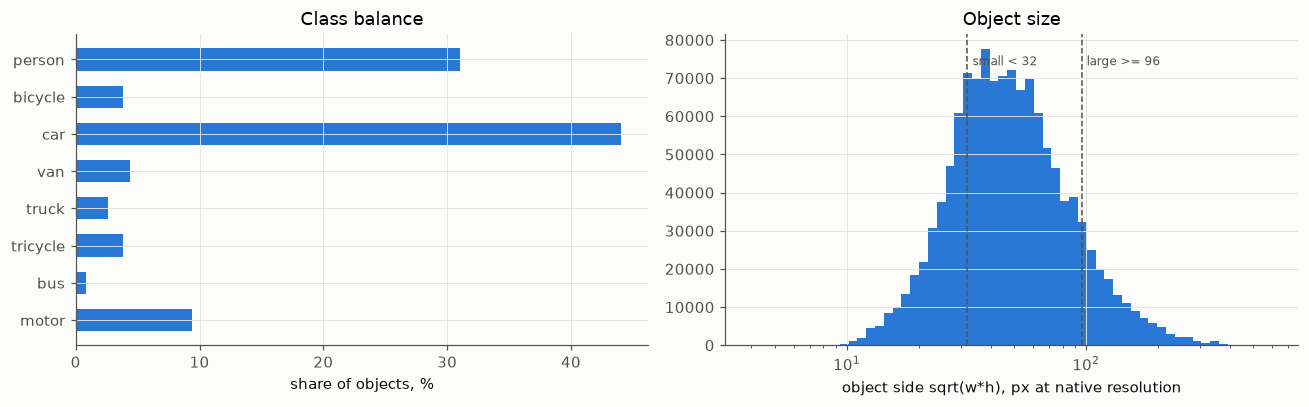

In [3]:
fig = eda.plot_classes_and_sizes(objects)
eda.size_table(objects)

## Density across clips
Each bar is one labelled clip coloured by its validation fold.

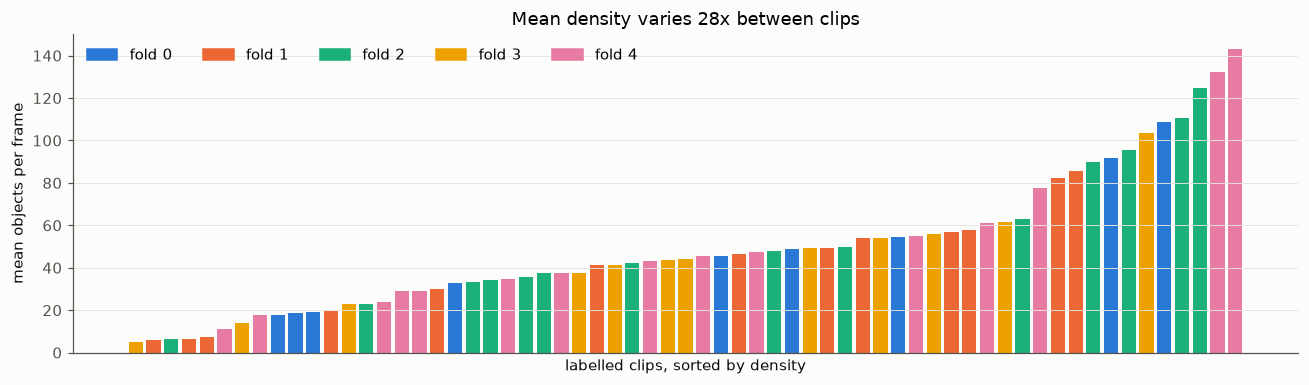

In [4]:
fig = eda.plot_clip_density(tables, folds)

## Resolution: labelled vs test frames
Share of frames per long-side bucket, %.

In [5]:
eda.resolution_shift(tables)

group,labelled,test
long_side,,
680,0.0,8.4
960,0.0,7.3
1344-1360,27.5,50.2
1904-1920,52.0,34.0
2688-3840,20.5,0.0


## Sharpness: labelled vs test frames
Variance of the Laplacian (higher = more fine detail) on 40 frames per size bucket. Labelled frames resized to the test sizes stay 2.4-3.6x sharper than the test frames, so the test video is softer (stronger compression or upscaling) at every size. The degraded validation frames (`evalb`: Gaussian blur sigma 0.5 up to 1000 px, 0.6 above, JPEG quality 60) were fitted to these numbers.

In [6]:
eda.sharpness_table(tables, os.environ.get("VISDET_CACHE", "../../hw2/cache"))

,test,"labelled, resized","labelled, degraded"
"long side, px",,,
680,559.0,1336.0,459.0
960,535.0,1280.0,465.0
1360,261.0,948.0,239.0
1920,210.0,767.0,231.0


## Temporal redundancy
IoU of the same tracked object between frame t and t+step. High IoU means the two frames carry almost the same supervision.

In [7]:
eda.temporal_overlap(tables)

,median IoU,share IoU < 0.5
step,,
1,0.895,0.047
2,0.806,0.148
5,0.591,0.412
10,0.348,0.612
20,0.093,0.746


## Conversion check
Converted boxes on original frames (colour = class in the order of the class table), ignored regions washed grey. Ignored regions are VisDrone crowds, dense parking and the `others` class; they are kept out of the loss by filling them with the padding grey in training images, and enter evaluation as `iscrowd` regions so detections there are neither rewarded nor penalised.

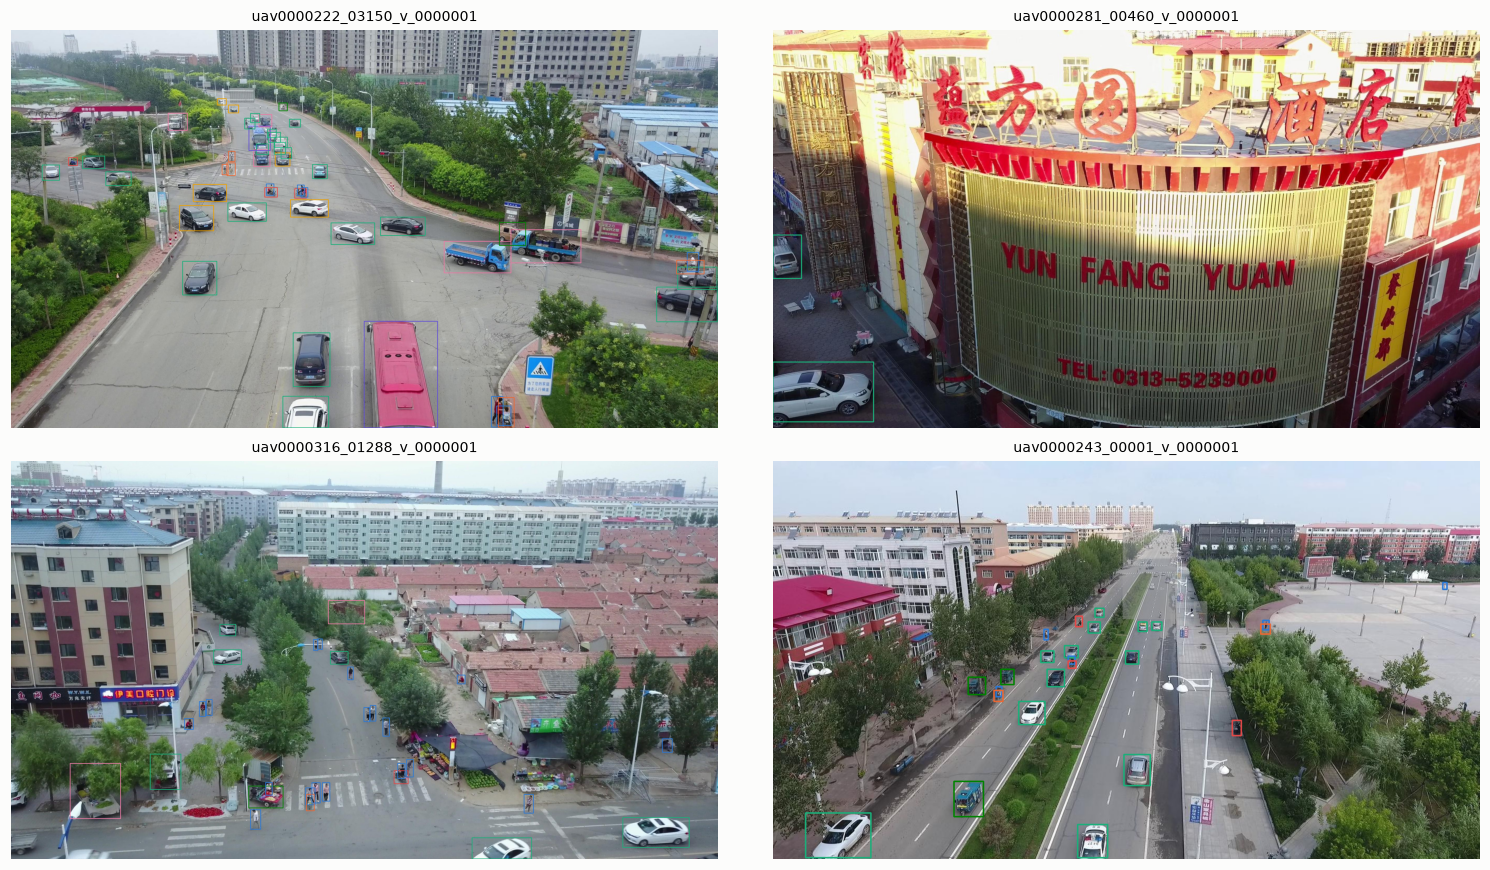

In [8]:
samples = folds.groupby("clip")["image_id"].first().sample(4, random_state=1)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, image_id in zip(axes.ravel(), samples, strict=False):
    ax.imshow(gallery.render_ground_truth(tables, image_id))
    ax.set_title(image_id, fontsize=9)
    ax.axis("off")
fig.tight_layout()

## Folds
Five folds grouped by source video, stratified by resolution and density (frozen in `src/visdet/data/clip_folds.csv`). Scored frames are windows of 75 consecutive frames (every third window), the length of a typical test clip, downscaled to the test size distribution.

In [9]:
folds.groupby("fold").agg(
    videos=("video", "nunique"),
    clips=("clip", "nunique"),
    frames=("image_id", "size"),
    scored=("scored", "sum"),
)

,videos,clips,frames,scored
fold,,,,
0,9,9,4740,1822
1,12,13,5742,2270
2,10,14,5289,2105
3,11,12,5233,1955
4,13,15,6043,2389


## Observations and decisions

| observation | decision |
|---|---|
| Several training clips come from one source video | folds grouped by source video; clips never split |
| Test clips are 35-148 consecutive frames | scored windows of 75 frames; temporal post-processing is possible on the test set |
| Median object side 46 px native, 31 px at 1280; 95% under 83 px at 1280 | input long side 1280; anchors and detection heads must reach 10-20 px objects |
| Up to 180 objects per frame | detection cap 500 per image, as on the leaderboard |
| Same-object IoU 0.59 at frame step 5 | train on every 5th frame; step 2 gave no gain at equal iterations (Kaggle pilot) |
| Test frames are smaller (15% at 680-960 px) and 2.4-3.6x blurrier than labelled frames | validation frames downscaled to the test sizes and degraded to the test sharpness; downscale and blur/JPEG augmentations |
| Car 44%, bicycle 4%, bus 0.8% of objects; mAP averages classes equally | per-class AP is reported; rare and thin classes limit mAP |
| Ignored regions in 72% of frames | painted grey in training images, `iscrowd` in evaluation |